# Ingeniería de variables para el pronóstico de demanda de MiBici
**Equipo 9 · Demanda por zona y hora**

## 1. Introducción
El pronóstico de la demanda permite anticipar los patrones de uso de MiBici y
apoyar la planeación territorial y horaria del servicio. Este análisis transforma
los viajes validados en observaciones por **zona y hora**, en continuidad con la
definición de negocio y la agregación territorial establecidas en el análisis exploratorio.

La demanda se representa mediante las **salidas de bicicletas durante la siguiente
hora**. Las llegadas se incorporan como objetivo complementario para estudiar los
flujos entre zonas. Ambas señales corresponden a viajes atendidos registrados;
la estimación de demanda insatisfecha requiere información adicional.

El resultado es un conjunto de datos estructurado para modelado, acompañado de
controles de calidad, trazabilidad de las fuentes y una definición explícita de
predictores y objetivos. El alcance comprende la preparación, validación y
exportación de los datos; la evaluación predictiva corresponde a la etapa de modelado.

## 2. Unidad de análisis y horizonte de pronóstico
Cada observación representa una zona geográfica durante una hora. La zonificación
utiliza una cuadrícula fija de **1 km**, consistente con el análisis exploratorio.
Su carácter es analítico y su aplicación operativa requiere validación con negocio.

| Elemento | Definición |
|---|---|
| Unidad territorial | Zona de la cuadrícula de 1 km |
| Frecuencia | Horaria |
| Objetivo principal | Salidas registradas durante la hora siguiente |
| Objetivo complementario | Llegadas registradas durante la hora siguiente |
| Referencia temporal | Hora recién cerrada |
| Información predictora | Calendario conocido y antecedentes disponibles |

Por ejemplo, una observación de **08:00 a 09:00** permite emitir a las **09:00** un
pronóstico para **09:00 a 10:00**. Esta separación distingue el periodo de referencia
del periodo que se desea anticipar.

Los datos de limpieza son retrospectivos. Antes del despliegue, la disponibilidad
de los conteos y sus validaciones deberá conciliarse con la latencia de actualización
del servicio. Los atributos que dependen de la finalización de viajes en curso,
como duración o velocidad, quedan fuera de los predictores seleccionados.

In [1]:
from pathlib import Path
import hashlib
import json
import sys

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Permite ejecutar desde la raíz del repositorio o desde notebooks/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'proyecto_mlops_equipo_9' / 'eda.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Abre el notebook desde este repositorio o su carpeta notebooks/.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from proyecto_mlops_equipo_9.config import CLEAN_DATA_DIR
from proyecto_mlops_equipo_9.dataset import cargar_estaciones
from proyecto_mlops_equipo_9.eda import zonificar

CELDA_M = 1000
FRECUENCIA = 'h'
REZAGOS_H = (1, 24, 168)
VENTANAS_H = (24, 168)
MIN_COBERTURA_MEDIA = 0.75
SILVER = CLEAN_DATA_DIR.parent
MANIFEST_PATH = SILVER / 'manifest.json'

# Hipótesis de trabajo: los archivos mensuales verificados contienen todos
# los viajes registrados. No significa demanda insatisfecha cero ni operación comprobada.
ASUMIR_COBERTURA_COMPLETA = True
# Intervalos [inicio, fin) de fallas conocidas, si el equipo los identifica.
PERIODOS_SIN_COBERTURA = []
EXPORTAR_DATASET = True
OUTPUT_PATH = ROOT / "data/processed/datos_feature_engineered_zona_hora.parquet"

pd.set_option('display.max_columns', 16)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True})
print('Raíz:', ROOT)
print('Insumos:', CLEAN_DATA_DIR)
print('Cobertura completa asumida:', ASUMIR_COBERTURA_COMPLETA)

Raíz: C:\Users\ferur\Documents\Tec_de_monterrey\Maestria_Inteligencia_Artificial\11MLOps\PROYECTO\main\Proyecto_MLOps_main
Insumos: C:\Users\ferur\Documents\Tec_de_monterrey\Maestria_Inteligencia_Artificial\11MLOps\PROYECTO\main\Proyecto_MLOps_main\data\silver\version_001\viajes
Cobertura completa asumida: True


2026-11-04 21:59:17.266 | INFO     | proyecto_mlops_equipo_9.config:<module>:11 - PROJ_ROOT path is: C:\Users\ferur\Documents\Tec_de_monterrey\Maestria_Inteligencia_Artificial\11MLOps\PROYECTO\main\Proyecto_MLOps_main


## 3. Fuentes y calidad de los insumos
Se utilizan los viajes aceptados por el proceso de limpieza y el catálogo de
estaciones asociado a la misma versión de datos. La integridad de los archivos
se comprueba mediante las huellas digitales y los conteos del manifiesto.

El procesamiento mensual limita el consumo de memoria y conserva la trazabilidad
de las fuentes. Los controles verifican continuidad entre meses, fechas válidas,
correspondencia con el periodo declarado y aceptación de los registros.

El catálogo representa una instantánea de las estaciones. Su alcance histórico
se considera al interpretar la ubicación y la disponibilidad territorial del servicio.

In [2]:
def sha256_archivo(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for bloque in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(bloque)
    return digest.hexdigest()

manifest = json.loads(MANIFEST_PATH.read_text(encoding='utf-8'))
archivos = sorted(CLEAN_DATA_DIR.glob('viajes_????_??.parquet'))
if not archivos:
    raise FileNotFoundError(f'No hay Parquet silver en {CLEAN_DATA_DIR}')
meses = pd.PeriodIndex([
    p.stem.removeprefix('viajes_').replace('_', '-')
    for p in archivos
], freq='M')
assert meses.is_unique
assert meses.equals(pd.period_range(meses.min(), meses.max(), freq='M')), 'Faltan meses intermedios'

catalogo_nombre = manifest['campos_control_constantes']['catalogo_version']
CATALOGO_PATH = SILVER / 'fuentes' / catalogo_nombre
assert sha256_archivo(CATALOGO_PATH) == manifest['campos_control_constantes']['catalogo_sha256']
estaciones = cargar_estaciones(CATALOGO_PATH)
assert estaciones['id'].notna().all() and estaciones['id'].is_unique

inicio_periodo = meses.min().start_time
fin_periodo = (meses.max() + 1).start_time  # límite exclusivo
horas = pd.date_range(inicio_periodo, fin_periodo, freq=FRECUENCIA, inclusive='left')
display(pd.DataFrame({'mes': meses.astype(str), 'archivo': [p.name for p in archivos]}))
print(f'{len(estaciones)} estaciones; {len(horas):,} horas nominales')

484 estaciones; 15,312 horas nominales


,mes,archivo
0,2025-01,viajes_2025_01.parquet
1,2025-02,viajes_2025_02.parquet
2,2025-03,viajes_2025_03.parquet
3,2025-04,viajes_2025_04.parquet
4,2025-05,viajes_2025_05.parquet
5,2025-06,viajes_2025_06.parquet
6,2025-07,viajes_2025_07.parquet
7,2025-08,viajes_2025_08.parquet
8,2025-09,viajes_2025_09.parquet
9,2025-10,viajes_2025_10.parquet


## 4. Asignación territorial
Las estaciones se asignan a una cuadrícula geográfica reproducible de 1 km, definida
independientemente del volumen de viajes. Cada evento conserva su correspondencia
con una zona de origen o destino.

Se verifica la unicidad de los identificadores del catálogo para preservar los
conteos durante la asignación. Las estaciones sin coordenadas válidas se reportan
como incidencias geográficas. Las zonas nuevas requieren acumular historia antes
de incorporarse al conjunto supervisado.

Estaciones sin zona: 0
Zonas de catálogo: 80


,id,latitude,longitude,zona_id
0,2,20.666378,-103.348820,G1000_-10753_2297
1,3,20.667228,-103.366000,G1000_-10754_2298
2,4,20.667690,-103.368252,G1000_-10755_2298
3,5,20.691847,-103.362549,G1000_-10754_2300
4,6,20.681158,-103.339363,G1000_-10752_2299
5,8,20.680717,-103.344415,G1000_-10752_2299
6,9,20.666771,-103.350562,G1000_-10753_2298
7,10,20.681953,-103.349992,G1000_-10753_2299
8,11,20.682077,-103.353835,G1000_-10753_2299
9,12,20.681852,-103.357338,G1000_-10754_2299


,estaciones
count,80.000000
mean,6.050000
std,3.897094
min,1.000000
25%,3.000000
50%,5.000000
75%,9.000000
max,17.000000


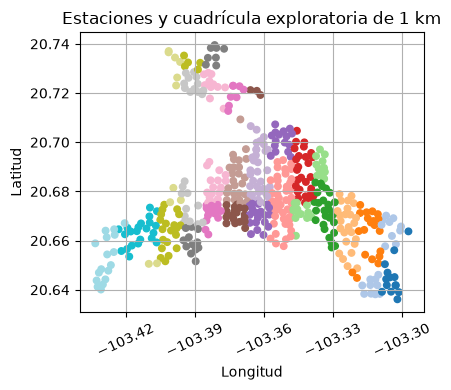

In [3]:
mapa_zonas = zonificar(estaciones, celda_m=CELDA_M).rename(columns={'zona': 'zona_id'})
assert mapa_zonas['id'].is_unique
mapa = mapa_zonas.set_index('id')['zona_id']
zonas = sorted(mapa.dropna().unique())
assert zonas, 'No hay zonas válidas en el catálogo'
display(mapa_zonas[['id', 'latitude', 'longitude', 'zona_id']].head(12))
resumen_zonas = (mapa_zonas.dropna(subset=['zona_id']).groupby('zona_id')
                 .agg(estaciones=('id', 'size')))
display(resumen_zonas.describe())
print('Estaciones sin zona:', mapa_zonas['zona_id'].isna().sum())
print('Zonas de catálogo:', len(zonas))

fig, ax = plt.subplots()
geo = mapa_zonas.dropna(subset=['zona_id'])
colores = pd.Categorical(geo['zona_id'], categories=zonas).codes
ax.scatter(geo.longitude, geo.latitude, c=colores, cmap='tab20', s=22)
ax.set(xlabel='Longitud', ylabel='Latitud', title='Estaciones y cuadrícula exploratoria de 1 km')
ax.set_aspect(1 / np.cos(np.radians(20.67)))
from matplotlib.ticker import MaxNLocator
ax.xaxis.set_major_locator(MaxNLocator(5))
ax.tick_params(axis='x', labelrotation=25)
plt.tight_layout()
plt.show()

## 5. Agregación de salidas y llegadas
Las salidas se contabilizan por zona de origen y hora de inicio; las llegadas,
por zona de destino y hora de finalización. Este criterio permite representar
los movimientos territoriales y asignar correctamente los viajes que cruzan
medianoche o un cambio de mes.

Se comprueba la conservación de los eventos respecto a los viajes de entrada.
Las llegadas del inicio del periodo se mantienen como desconocidas durante un
margen equivalente a la mayor duración observada, debido a la falta de viajes
iniciados antes de las fuentes disponibles. Los eventos posteriores al cierre
del periodo se contabilizan por separado.

In [4]:
salidas_partes, llegadas_partes, auditoria = [], [], []
duracion_max = pd.Timedelta(0)
salidas_fuera = llegadas_fuera = 0
salidas_sin_zona = llegadas_sin_zona = 0
filas_silver = 0
productos_manifest = {item['archivo']: item for item in manifest['salidas']}

def contar_eventos(df, fecha, zona):
    return (df.assign(inicio_hora=df[fecha].dt.floor(FRECUENCIA))
            .groupby([zona, 'inicio_hora']).size()
            .rename_axis(index=['zona_id', 'inicio_hora']))

for archivo, mes in zip(archivos, meses):
    registro = productos_manifest[archivo.relative_to(SILVER).as_posix()]
    assert sha256_archivo(archivo) == registro['sha256'], f'Cambió {archivo.name}'
    schema = pq.read_schema(archivo)
    columnas = ['inicio', 'fin', 'origen_id', 'destino_id', 'es_valido']
    assert set(columnas).issubset(schema.names), f'Columnas faltantes en {archivo.name}'
    df = pd.read_parquet(archivo, columns=columnas)
    assert len(df) == registro['filas']
    assert df['es_valido'].eq(True).all(), f'Silver contiene viajes no aceptados: {archivo.name}'
    for col in ['inicio', 'fin']:
        df[col] = pd.to_datetime(df[col], errors='raise')
        assert df[col].notna().all()
        assert df[col].dt.tz is None, 'Revisar contrato de zona horaria antes de continuar'
    assert df['inicio'].dt.to_period('M').eq(mes).all(), 'Inicio fuera del mes del archivo'
    assert df['fin'].gt(df['inicio']).all()
    duracion_max = max(duracion_max, (df['fin'] - df['inicio']).max())
    df['zona_origen'] = df['origen_id'].map(mapa)
    df['zona_destino'] = df['destino_id'].map(mapa)
    sin_origen = int(df['zona_origen'].isna().sum())
    sin_destino = int(df['zona_destino'].isna().sum())
    dentro_inicio = df['inicio'].ge(inicio_periodo) & df['inicio'].lt(fin_periodo)
    dentro_fin = df['fin'].ge(inicio_periodo) & df['fin'].lt(fin_periodo)
    salidas_partes.append(contar_eventos(df.loc[dentro_inicio], 'inicio', 'zona_origen'))
    llegadas_partes.append(contar_eventos(df.loc[dentro_fin], 'fin', 'zona_destino'))
    salidas_fuera += int((~dentro_inicio & df['zona_origen'].notna()).sum())
    llegadas_fuera += int((~dentro_fin & df['zona_destino'].notna()).sum())
    salidas_sin_zona += sin_origen
    llegadas_sin_zona += sin_destino
    filas_silver += len(df)
    auditoria.append({'mes': str(mes), 'viajes': len(df),
                     'sin_zona_origen': sin_origen, 'sin_zona_destino': sin_destino})
    del df

salidas = pd.concat(salidas_partes).groupby(level=[0, 1]).sum().rename('salidas')
llegadas = pd.concat(llegadas_partes).groupby(level=[0, 1]).sum().rename('llegadas')
conteos = pd.concat([salidas, llegadas], axis=1).sort_index()
auditoria = pd.DataFrame(auditoria)
assert int(salidas.sum()) + salidas_sin_zona + salidas_fuera == filas_silver
assert int(llegadas.sum()) + llegadas_sin_zona + llegadas_fuera == filas_silver
display(auditoria)
print('Viajes silver:', f'{filas_silver:,}')
print('Eventos con zona fuera del periodo:', {'salidas': salidas_fuera, 'llegadas': llegadas_fuera})
print('Duración máxima observada:', duracion_max)

Viajes silver: 7,644,409
Eventos con zona fuera del periodo: {'salidas': 0, 'llegadas': 16}
Duración máxima observada: 0 days 02:59:49


,mes,viajes,sin_zona_origen,sin_zona_destino
0,2025-01,370915,0,0
1,2025-02,363530,0,0
2,2025-03,394765,0,0
3,2025-04,357088,0,0
4,2025-05,385864,0,0
5,2025-06,346867,0,0
6,2025-07,358424,0,0
7,2025-08,364639,0,0
8,2025-09,366582,0,0
9,2025-10,409509,0,0


## 6. Cobertura temporal y tratamiento de ausencias
El calendario incluye todas las combinaciones de zona y hora del periodo. Para
interpretar las ausencias se adopta la hipótesis de que los archivos mensuales
verificados contienen la totalidad de los viajes registrados.

| Situación | Tratamiento |
|---|---|
| Hora cubierta, posterior a la primera actividad de una zona y sin eventos zonales | Cero viajes registrados |
| Periodo anterior a la primera actividad observada de una zona | Valor desconocido |
| Hora sin salidas ni llegadas en toda la red | Cobertura dudosa; valor desconocido |
| Falla de cobertura identificada | Valor desconocido |
| Periodo fuera de las fuentes disponibles | Valor desconocido |

La primera observación de una zona no establece su fecha de inauguración. Del mismo
modo, la presencia de actividad en la red constituye una señal de cobertura, pero
no garantiza completitud. Estas hipótesis deberán contrastarse con información operativa.

Los rezagos requieren un dato observado en la hora correspondiente. Las medias
de 24 y 168 horas se calculan después de completar la duración de cada ventana
desde la primera actividad zonal y exigen al menos **75% de horas observadas**.
La proporción observada se incorpora como predictor para representar la calidad
de la historia disponible. Este umbral se evaluará durante la validación temporal.

In [5]:
def construir_panel(conteos_fuente, zonas_catalogo, horas_calendario,
                    asumir_cobertura=True, periodos_sin_cobertura=()):
    indice = pd.MultiIndex.from_product(
        [zonas_catalogo, horas_calendario], names=['zona_id', 'inicio_hora'])
    out = conteos_fuente.reindex(indice).reset_index()
    primera = (conteos_fuente.dropna(how='all').reset_index()
               .groupby('zona_id')['inicio_hora'].min())
    out['primera_hora_observada_zona'] = out['zona_id'].map(primera)
    out['zona_observada'] = out['inicio_hora'].ge(out['primera_hora_observada_zona'])
    actividad_red = conteos_fuente.groupby(level='inicio_hora').sum(min_count=1).sum(axis=1)
    out['cobertura_horaria_asumida'] = (
        out['inicio_hora'].map(actividad_red).fillna(0).gt(0) & bool(asumir_cobertura))
    for inicio, fin in periodos_sin_cobertura:
        assert pd.Timestamp(inicio) < pd.Timestamp(fin)
        out.loc[out['inicio_hora'].ge(pd.Timestamp(inicio)) &
                out['inicio_hora'].lt(pd.Timestamp(fin)), 'cobertura_horaria_asumida'] = False
    elegible = out['zona_observada'] & out['cobertura_horaria_asumida']
    for variable in ['salidas', 'llegadas']:
        out[f'{variable}_sin_registros'] = out[variable].isna()
        out[f'{variable}_cero_asumido'] = out[variable].isna() & elegible
        if asumir_cobertura:
            out.loc[elegible, variable] = out.loc[elegible, variable].fillna(0)
            out.loc[~elegible, variable] = np.nan
        out[variable] = out[variable].astype('Float64')
    return out

panel = construir_panel(conteos, zonas, horas, ASUMIR_COBERTURA_COMPLETA,
                        PERIODOS_SIN_COBERTURA)
fin_margen_llegadas = (inicio_periodo + duracion_max).ceil(FRECUENCIA)
panel['llegadas_borde_inicial'] = panel['inicio_hora'].lt(fin_margen_llegadas)
panel.loc[panel['llegadas_borde_inicial'], 'llegadas'] = pd.NA
panel.loc[panel['llegadas_borde_inicial'], 'llegadas_cero_asumido'] = False
panel['instante_emision'] = panel['inicio_hora'] + pd.Timedelta(hours=1)
panel['inicio_hora_objetivo'] = panel['instante_emision']
panel['fin_hora_objetivo'] = panel['instante_emision'] + pd.Timedelta(hours=1)

assert not panel.duplicated(['zona_id', 'inicio_hora']).any()
assert panel.groupby('zona_id')['inicio_hora'].diff().dropna().eq(pd.Timedelta(hours=1)).all()
assert len(panel) == len(zonas) * len(horas)
assert panel.loc[~panel['zona_observada'], ['salidas', 'llegadas']].isna().all().all()
if ASUMIR_COBERTURA_COMPLETA:
    assert panel.loc[~panel['cobertura_horaria_asumida'], ['salidas', 'llegadas']].isna().all().all()
display(panel.head(10))
print(f'Panel: {len(zonas)} zonas × {len(horas):,} horas = {len(panel):,} filas')
print('Horas globales con cobertura dudosa:',
      panel.loc[~panel.cobertura_horaria_asumida, 'inicio_hora'].nunique())
print('Filas previas a primera observación zonal:', int((~panel.zona_observada).sum()))

Panel: 80 zonas × 15,312 horas = 1,224,960 filas
Horas globales con cobertura dudosa: 1853
Filas previas a primera observación zonal: 194624


,zona_id,inicio_hora,salidas,llegadas,primera_hora_observada_zona,zona_observada,cobertura_horaria_asumida,salidas_sin_registros,salidas_cero_asumido,llegadas_sin_registros,llegadas_cero_asumido,llegadas_borde_inicial,instante_emision,inicio_hora_objetivo,fin_hora_objetivo
0,G1000_-10747_2297,2025-01-01 00:00:00,<NA>,<NA>,2026-06-17 15:00:00,False,True,True,False,True,False,True,2025-01-01 01:00:00,2025-01-01 01:00:00,2025-01-01 02:00:00
1,G1000_-10747_2297,2025-01-01 01:00:00,<NA>,<NA>,2026-06-17 15:00:00,False,True,True,False,True,False,True,2025-01-01 02:00:00,2025-01-01 02:00:00,2025-01-01 03:00:00
2,G1000_-10747_2297,2025-01-01 02:00:00,<NA>,<NA>,2026-06-17 15:00:00,False,False,True,False,True,False,True,2025-01-01 03:00:00,2025-01-01 03:00:00,2025-01-01 04:00:00
3,G1000_-10747_2297,2025-01-01 03:00:00,<NA>,<NA>,2026-06-17 15:00:00,False,False,True,False,True,False,False,2025-01-01 04:00:00,2025-01-01 04:00:00,2025-01-01 05:00:00
4,G1000_-10747_2297,2025-01-01 04:00:00,<NA>,<NA>,2026-06-17 15:00:00,False,False,True,False,True,False,False,2025-01-01 05:00:00,2025-01-01 05:00:00,2025-01-01 06:00:00
5,G1000_-10747_2297,2025-01-01 05:00:00,<NA>,<NA>,2026-06-17 15:00:00,False,True,True,False,True,False,False,2025-01-01 06:00:00,2025-01-01 06:00:00,2025-01-01 07:00:00
6,G1000_-10747_2297,2025-01-01 06:00:00,<NA>,<NA>,2026-06-17 15:00:00,False,True,True,False,True,False,False,2025-01-01 07:00:00,2025-01-01 07:00:00,2025-01-01 08:00:00
7,G1000_-10747_2297,2025-01-01 07:00:00,<NA>,<NA>,2026-06-17 15:00:00,False,True,True,False,True,False,False,2025-01-01 08:00:00,2025-01-01 08:00:00,2025-01-01 09:00:00
8,G1000_-10747_2297,2025-01-01 08:00:00,<NA>,<NA>,2026-06-17 15:00:00,False,True,True,False,True,False,False,2025-01-01 09:00:00,2025-01-01 09:00:00,2025-01-01 10:00:00
9,G1000_-10747_2297,2025-01-01 09:00:00,<NA>,<NA>,2026-06-17 15:00:00,False,True,True,False,True,False,False,2025-01-01 10:00:00,2025-01-01 10:00:00,2025-01-01 11:00:00


## 7. Definición y validación de los objetivos
Los objetivos corresponden a las salidas y llegadas de la hora inmediatamente
posterior a cada observación. La asignación se realiza dentro de cada zona sobre
un calendario continuo, preservando como desconocido el futuro sin datos disponibles.

Los ejemplos controlados permiten comprobar la separación entre pasado y futuro,
la correspondencia del horizonte y la independencia entre zonas. También muestran
la diferencia entre una ventana retrospectiva y la suma de intervalos futuros.

In [6]:
demo_15m = pd.DataFrame({
    'inicio_intervalo': pd.date_range('2026-01-01 08:00', periods=8, freq='15min'),
    'salidas': [1, 2, 3, 4, 5, 6, 7, 8],
})
demo_15m['formula_anterior'] = demo_15m['salidas'].shift(-1).rolling(4).sum()
demo_15m['suma_4_futuras'] = sum(demo_15m['salidas'].shift(-k) for k in range(1, 5))
assert demo_15m.loc[3, 'formula_anterior'] == 14
assert demo_15m.loc[3, 'suma_4_futuras'] == 26
display(demo_15m)

def agregar_objetivos(frame):
    out = frame.sort_values(['zona_id', 'inicio_hora']).copy()
    for variable in ['salidas', 'llegadas']:
        out[f'{variable}_siguiente_hora'] = out.groupby('zona_id')[variable].shift(-1)
    return out

demo = pd.DataFrame({
    'zona_id': ['A'] * 3 + ['B'] * 3,
    'inicio_hora': list(pd.date_range('2026-01-01 08:00', periods=3, freq='h')) * 2,
    'salidas': [10, 20, 30, 100, 200, 300],
    'llegadas': [3, 5, 7, 30, 50, 70],
})
demo = agregar_objetivos(demo)
assert demo['salidas_siguiente_hora'].iloc[[0, 1, 3, 4]].tolist() == [20, 30, 200, 300]
assert demo.groupby('zona_id').tail(1)['salidas_siguiente_hora'].isna().all()
display(demo)
panel = agregar_objetivos(panel)
OBJETIVOS = ['salidas_siguiente_hora', 'llegadas_siguiente_hora']

,inicio_intervalo,salidas,formula_anterior,suma_4_futuras
0,2026-01-01 08:00:00,1,NaN,14.0
1,2026-01-01 08:15:00,2,NaN,18.0
2,2026-01-01 08:30:00,3,NaN,22.0
3,2026-01-01 08:45:00,4,14.0,26.0
4,2026-01-01 09:00:00,5,18.0,NaN
5,2026-01-01 09:15:00,6,22.0,NaN
6,2026-01-01 09:30:00,7,26.0,NaN
7,2026-01-01 09:45:00,8,NaN,NaN


,zona_id,inicio_hora,salidas,llegadas,salidas_siguiente_hora,llegadas_siguiente_hora
0,A,2026-01-01 08:00:00,10,3,20.0,5.0
1,A,2026-01-01 09:00:00,20,5,30.0,7.0
2,A,2026-01-01 10:00:00,30,7,NaN,NaN
3,B,2026-01-01 08:00:00,100,30,200.0,50.0
4,B,2026-01-01 09:00:00,200,50,300.0,70.0
5,B,2026-01-01 10:00:00,300,70,NaN,NaN


## 8. Variables predictoras
La selección de variables representa la actividad reciente, los patrones recurrentes
y el calendario de la hora que se desea pronosticar.

| Grupo | Variables |
|---|---|
| Actividad reciente | Salidas y llegadas de la hora cerrada |
| Antecedentes | Rezagos de 1, 24 y 168 horas respecto a la hora de referencia |
| Tendencia histórica | Medias previas de 24 y 168 horas |
| Calidad de la historia | Fracción observada en cada ventana |
| Calendario | Hora, día, mes, año, fin de semana y periodo pico |
| Periodicidad | Representaciones cíclicas de hora y día de la semana |
| Territorio | Identificador categórico de zona |

Las medias utilizan exclusivamente horas anteriores a la de referencia. Los
faltantes de los rezagos se conservan, sin interpolación con valores futuros.
La definición de hora pico es una regla inicial sujeta a evaluación.

Los procedimientos de codificación, imputación o escalado se ajustarán únicamente
con los datos de entrenamiento al definir el esquema de evaluación.

In [7]:
def agregar_historia(frame):
    out = frame.sort_values(['zona_id', 'inicio_hora']).copy()
    for variable in ['salidas', 'llegadas']:
        grupo = out.groupby('zona_id')[variable]
        for lag in REZAGOS_H:
            out[f'{variable}_lag_{lag}h'] = grupo.shift(lag)
        for ventana in VENTANAS_H:
            out[f'{variable}_media_previa_{ventana}h'] = grupo.transform(
                lambda s: s.shift(1).rolling(ventana, min_periods=int(np.ceil(
                    MIN_COBERTURA_MEDIA * ventana))).mean())
            out[f'{variable}_cobertura_previa_{ventana}h'] = grupo.transform(
                lambda s: s.shift(1).rolling(ventana, min_periods=1).count() / ventana)
            if 'primera_hora_observada_zona' in out:
                ventana_transcurrida = (out['inicio_hora'] - out['primera_hora_observada_zona']).ge(
                    pd.Timedelta(hours=ventana))
            else:
                ventana_transcurrida = out.groupby('zona_id').cumcount().ge(ventana)
            out.loc[~ventana_transcurrida, f'{variable}_media_previa_{ventana}h'] = np.nan
    return out

panel = agregar_historia(panel)
fecha = panel['inicio_hora_objetivo'].dt
panel['hora_objetivo'] = fecha.hour
panel['dia_semana_objetivo'] = fecha.dayofweek
panel['dia_mes_objetivo'] = fecha.day
panel['mes_objetivo'] = fecha.month
panel['dia_anio_objetivo'] = fecha.dayofyear
panel['anio_objetivo'] = fecha.year
panel['es_fin_semana'] = fecha.dayofweek.ge(5).astype('int8')
# Se conserva la regla heurística del notebook FV; no es una regla operativa validada.
panel['es_hora_pico'] = (fecha.hour.between(7, 9) | fecha.hour.between(16, 19)).astype('int8')
panel['hora_sin'] = np.sin(2 * np.pi * fecha.hour / 24)
panel['hora_cos'] = np.cos(2 * np.pi * fecha.hour / 24)
panel['dia_semana_sin'] = np.sin(2 * np.pi * fecha.dayofweek / 7)
panel['dia_semana_cos'] = np.cos(2 * np.pi * fecha.dayofweek / 7)

FEATURES_HISTORICAS = ['salidas', 'llegadas'] + [c for c in panel if '_lag_' in c or '_media_previa_' in c or '_cobertura_previa_' in c]
FEATURES_CALENDARIO = ['hora_objetivo', 'dia_semana_objetivo', 'dia_mes_objetivo',
    'mes_objetivo', 'dia_anio_objetivo', 'anio_objetivo', 'es_fin_semana',
    'es_hora_pico', 'hora_sin', 'hora_cos', 'dia_semana_sin', 'dia_semana_cos']
FEATURES = ['zona_id'] + FEATURES_HISTORICAS + FEATURES_CALENDARIO
assert not set(FEATURES) & set(OBJETIVOS)
display(panel[['zona_id', 'inicio_hora', 'instante_emision', 'salidas',
               'salidas_lag_1h', 'salidas_lag_24h', 'salidas_media_previa_24h',
               'salidas_siguiente_hora']].head(30))

<ipython-input-7-9c8d54a1f5e9>:24: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  panel['dia_semana_objetivo'] = fecha.dayofweek
<ipython-input-7-9c8d54a1f5e9>:27: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  panel['dia_anio_objetivo'] = fecha.dayofyear
<ipython-input-7-9c8d54a1f5e9>:29: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  panel['es_fin_semana'] = fecha.dayofweek.ge(5).astype('int8')
<ipython-input-7-9c8d54a1f5e9>:34: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  panel['dia_semana_sin'] = np.sin(2 * np.pi * fecha.dayofweek / 7)
<ipython-input-7-9c8d54a1f5e9>:35: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Us

,zona_id,inicio_hora,instante_emision,salidas,salidas_lag_1h,salidas_lag_24h,salidas_media_previa_24h,salidas_siguiente_hora
0,G1000_-10747_2297,2025-01-01 00:00:00,2025-01-01 01:00:00,<NA>,<NA>,<NA>,NaN,<NA>
1,G1000_-10747_2297,2025-01-01 01:00:00,2025-01-01 02:00:00,<NA>,<NA>,<NA>,NaN,<NA>
2,G1000_-10747_2297,2025-01-01 02:00:00,2025-01-01 03:00:00,<NA>,<NA>,<NA>,NaN,<NA>
3,G1000_-10747_2297,2025-01-01 03:00:00,2025-01-01 04:00:00,<NA>,<NA>,<NA>,NaN,<NA>
4,G1000_-10747_2297,2025-01-01 04:00:00,2025-01-01 05:00:00,<NA>,<NA>,<NA>,NaN,<NA>
5,G1000_-10747_2297,2025-01-01 05:00:00,2025-01-01 06:00:00,<NA>,<NA>,<NA>,NaN,<NA>
6,G1000_-10747_2297,2025-01-01 06:00:00,2025-01-01 07:00:00,<NA>,<NA>,<NA>,NaN,<NA>
7,G1000_-10747_2297,2025-01-01 07:00:00,2025-01-01 08:00:00,<NA>,<NA>,<NA>,NaN,<NA>
8,G1000_-10747_2297,2025-01-01 08:00:00,2025-01-01 09:00:00,<NA>,<NA>,<NA>,NaN,<NA>
9,G1000_-10747_2297,2025-01-01 09:00:00,2025-01-01 10:00:00,<NA>,<NA>,<NA>,NaN,<NA>


## 9. Controles de consistencia
La validación comprueba la continuidad horaria, la unicidad de las observaciones,
la conservación de eventos y la correspondencia de los objetivos con el periodo futuro.

Una prueba de perturbación verifica que modificar conteos futuros preserve las
variables históricas de observaciones anteriores y de otras zonas. Los casos
controlados también revisan la asignación de ceros, las ausencias de cobertura
y los periodos previos a la primera actividad territorial.

In [8]:
# Referencia independiente: buscar el conteo por la hora objetivo y la zona.
referencia = panel[['zona_id', 'inicio_hora', 'salidas', 'llegadas']].rename(columns={
    'inicio_hora': 'inicio_hora_objetivo',
    'salidas': 'salidas_esperadas', 'llegadas': 'llegadas_esperadas'})
comprobacion = panel[['zona_id', 'inicio_hora_objetivo', *OBJETIVOS]].merge(
    referencia, on=['zona_id', 'inicio_hora_objetivo'], how='left', validate='one_to_one')
for variable in ['salidas', 'llegadas']:
    pd.testing.assert_series_equal(
        comprobacion[f'{variable}_siguiente_hora'],
        comprobacion[f'{variable}_esperadas'], check_names=False, check_dtype=False)
    assert panel.groupby('zona_id').tail(1)[f'{variable}_siguiente_hora'].isna().all()
    assert panel[variable].dropna().ge(0).all()
    assert panel[variable].dropna().mod(1).eq(0).all()

observadas = panel.loc[~panel['salidas_sin_registros'], 'salidas'].sum()
excluidas_cobertura = panel.loc[~panel['cobertura_horaria_asumida'], ['zona_id', 'inicio_hora']]
conteos_excluidos = excluidas_cobertura.merge(
    salidas.reset_index(), on=['zona_id', 'inicio_hora'], how='left')['salidas'].sum()
assert int(observadas + conteos_excluidos) == int(salidas.sum())
# Las llegadas del borde se enmascaran solo en el panel; el conteo fuente se conserva.
assert int(llegadas.sum()) + llegadas_sin_zona + llegadas_fuera == filas_silver

sintetico = pd.DataFrame({
    'zona_id': ['A'] * 200 + ['B'] * 200,
    'inicio_hora': list(pd.date_range('2026-01-01', periods=200, freq='h')) * 2,
    'salidas': np.arange(400, dtype=float), 'llegadas': np.arange(400, dtype=float) + 2,
})
base = agregar_historia(sintetico)
alterado = sintetico.copy()
alterado.loc[180, ['salidas', 'llegadas']] = 99999
despues = agregar_historia(alterado)
historia_cols = [c for c in base if '_lag_' in c or '_media_previa_' in c or '_cobertura_previa_' in c]
pd.testing.assert_frame_equal(base.loc[:179, historia_cols], despues.loc[:179, historia_cols])
pd.testing.assert_frame_equal(base.loc[200:, historia_cols], despues.loc[200:, historia_cols])
assert base.loc[0, 'salidas_lag_1h'] != base.loc[0, 'salidas_lag_1h']  # NaN inicial
assert base.loc[200, 'salidas_media_previa_24h'] != base.loc[200, 'salidas_media_previa_24h']
print('Validaciones superadas: calendario, objetivos, conservación y ausencia de anticipación en historia.')

# Caso pequeño: cero zonal válido, sin inventar historia previa ni una falla global.
horas_prueba = pd.date_range('2026-01-01', periods=5, freq='h')
fuente_prueba = pd.DataFrame({
    'zona_id': ['A', 'A', 'A', 'B'],
    'inicio_hora': [horas_prueba[0], horas_prueba[1], horas_prueba[3], horas_prueba[1]],
    'salidas': [2., 3., 4., 1.], 'llegadas': [2., 3., 4., 1.],
}).set_index(['zona_id', 'inicio_hora'])
prueba_panel = construir_panel(fuente_prueba, ['A', 'B'], horas_prueba).set_index(['zona_id', 'inicio_hora'])
assert pd.isna(prueba_panel.loc[('B', horas_prueba[0]), 'salidas'])
assert prueba_panel.loc[('B', horas_prueba[3]), 'salidas'] == 0
assert prueba_panel.loc[('B', horas_prueba[3]), 'salidas_cero_asumido']
assert prueba_panel.loc[(slice(None), horas_prueba[2]), 'salidas'].isna().all()
falla = construir_panel(fuente_prueba, ['A', 'B'], horas_prueba,
                        periodos_sin_cobertura=[(horas_prueba[1], horas_prueba[2])])
assert falla.loc[falla.inicio_hora.eq(horas_prueba[1]), ['salidas', 'llegadas']].isna().all().all()
print('Regla de ceros validada: zona observada, cobertura y fallas explícitas.')


Validaciones superadas: calendario, objetivos, conservación y ausencia de anticipación en historia.
Regla de ceros validada: zona observada, cobertura y fallas explícitas.


## 10. Selección de observaciones para modelado
El conjunto supervisado conserva las observaciones con predictores completos,
ambos objetivos disponibles y un horizonte contenido en el periodo de las fuentes.
Las horas con **cero viajes registrados permanecen incluidas**.

Las exclusiones se clasifican por objetivo desconocido, historia insuficiente o
horizonte fuera del periodo. El balance presenta categorías excluyentes para
cuantificar el efecto de cada criterio sobre el conjunto final.

La evaluación posterior deberá utilizar cortes cronológicos comunes para todas
las zonas. Los objetivos de entrenamiento deberán finalizar antes del comienzo
de validación, y los transformadores se ajustarán exclusivamente con entrenamiento.

,resultado
meses_fuente,21
viajes_silver,7644409
zonas_catalogo,80
horas_nominales,15312
filas_panel,1224960
predictores_candidatos,29
objetivos,2
filas_con_ambos_objetivos,905729
filas_con_historia_y_objetivos,806774
salidas_sin_zona,0


,faltantes_pct
salidas,26.06
llegadas,26.06
salidas_lag_1h,26.06
salidas_lag_24h,26.19
salidas_lag_168h,27.02
salidas_media_previa_24h,16.19
salidas_cobertura_previa_24h,0.00
salidas_media_previa_168h,16.99
salidas_cobertura_previa_168h,0.00
llegadas_lag_1h,26.07


,salidas_siguiente_hora,llegadas_siguiente_hora
count,905753.0,905729.0
mean,8.43979,8.439996
std,15.395745,15.651771
min,0.0,0.0
25%,1.0,1.0
50%,3.0,3.0
75%,8.0,8.0
max,315.0,312.0


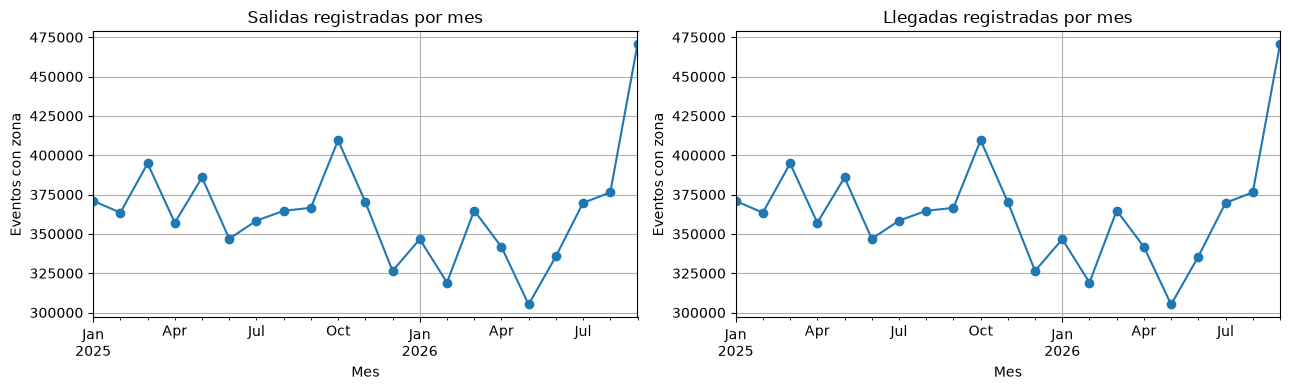

**Política aplicada:** ceros bajo hipótesis de cobertura, después de primera actividad zonal; huecos globales y fallas conocidas permanecen desconocidos.

In [9]:
resumen = pd.Series({
    'meses_fuente': len(meses), 'viajes_silver': filas_silver,
    'zonas_catalogo': len(zonas), 'horas_nominales': len(horas),
    'filas_panel': len(panel), 'predictores_candidatos': len(FEATURES),
    'objetivos': len(OBJETIVOS),
    'filas_con_ambos_objetivos': int(panel[OBJETIVOS].notna().all(axis=1).sum()),
    'filas_con_historia_y_objetivos': int(panel[FEATURES + OBJETIVOS].notna().all(axis=1).sum()),
    'salidas_sin_zona': salidas_sin_zona, 'llegadas_sin_zona': llegadas_sin_zona,
}, name='resultado')
display(resumen.to_frame())
display((panel[FEATURES_HISTORICAS + OBJETIVOS].isna().mean() * 100)
        .round(2).rename('faltantes_pct').to_frame())
display(panel[OBJETIVOS].describe())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, variable in zip(axes, ['salidas', 'llegadas']):
    # Se grafica el conteo fuente; los huecos del panel no se presentan como ceros.
    mensual = (conteos[variable].groupby(
        conteos.index.get_level_values('inicio_hora').to_period('M')).sum(min_count=1))
    mensual.plot(ax=ax, marker='o')
    ax.set(title=f'{variable.capitalize()} registradas por mes', xlabel='Mes', ylabel='Eventos con zona')
plt.tight_layout()
plt.show()

display(Markdown('**Política aplicada:** ceros bajo hipótesis de cobertura, después de primera actividad zonal; huecos globales y fallas conocidas permanecen desconocidos.'))

## 11. Estructura del conjunto de datos
El archivo final separa las variables de modelado de la información necesaria
para trazabilidad y partición temporal.

| Grupo | Contenido | Aplicación |
|---|---|---|
| Predictores | Zona, actividad histórica, cobertura y calendario | Entradas del modelo |
| Objetivos | Salidas y llegadas de la siguiente hora | Variables por pronosticar |
| Auditoría | Fechas, cobertura y criterios de asignación de ceros | Trazabilidad y partición |

El contrato de datos identifica cada columna y su tipo. La zona se conserva como
categoría y los objetivos se ubican al final del archivo. Los campos de auditoría
se mantienen separados de las entradas del modelo.

El conjunto está orientado a experimentación retrospectiva. Su uso operativo
requiere verificar la disponibilidad de los datos al emitir cada pronóstico y
adaptar las variables a los tiempos reales de actualización.

In [10]:
AUDITORIA = ['inicio_hora', 'instante_emision', 'inicio_hora_objetivo',
    'fin_hora_objetivo', 'primera_hora_observada_zona', 'zona_observada',
    'cobertura_horaria_asumida', 'salidas_sin_registros', 'llegadas_sin_registros',
    'salidas_cero_asumido', 'llegadas_cero_asumido', 'llegadas_borde_inicial']
objetivos_completos = panel[OBJETIVOS].notna().all(axis=1)
historia_completa = panel[FEATURES].notna().all(axis=1)
horizonte_observado = panel['fin_hora_objetivo'].le(fin_periodo)
motivo = np.select(
    [~objetivos_completos, ~historia_completa, ~horizonte_observado],
    ['objetivo_desconocido', 'historia_incompleta', 'fuera_del_periodo'], default='incluida')
balance = pd.Series(motivo).value_counts().rename_axis('estado').rename('filas')
display(balance.to_frame())
assert int(balance.sum()) == len(panel)

columnas_finales = AUDITORIA + FEATURES + OBJETIVOS
assert len(columnas_finales) == len(set(columnas_finales))
dataset_final = (panel.loc[motivo == 'incluida', columnas_finales]
                 .sort_values(['inicio_hora_objetivo', 'zona_id']).reset_index(drop=True))
assert not dataset_final.empty, 'La política actual no produce filas supervisadas; revisar cobertura e historia.'
assert dataset_final[FEATURES + OBJETIVOS].notna().all().all()
assert not dataset_final.duplicated(['zona_id', 'inicio_hora_objetivo']).any()
assert dataset_final['fin_hora_objetivo'].le(fin_periodo).all()
assert dataset_final['inicio_hora_objetivo'].is_monotonic_increasing
assert np.isfinite(dataset_final[FEATURES_HISTORICAS + FEATURES_CALENDARIO + OBJETIVOS]
                   .to_numpy(dtype=float)).all()
for variable in ['salidas', 'llegadas', *OBJETIVOS]:
    assert dataset_final[variable].mod(1).eq(0).all()
    dataset_final[variable] = dataset_final[variable].astype('int32')
dataset_final['zona_id'] = dataset_final['zona_id'].astype('string')

ceros = dataset_final[OBJETIVOS].eq(0).sum().rename('objetivos_cero_conservados')
display(ceros.to_frame())
assert ceros.gt(0).all(), 'Revisar que la selección no haya eliminado los objetivos cero.'
display(dataset_final.head())
print('Dataset final:', dataset_final.shape)
print('Predictores:', len(FEATURES), '| Objetivos:', len(OBJETIVOS), '| Auditoría:', len(AUDITORIA))

Dataset final: (806774, 43)
Predictores: 29 | Objetivos: 2 | Auditoría: 12


,filas
estado,
incluida,806774
objetivo_desconocido,319231
historia_incompleta,98955


,objetivos_cero_conservados
salidas_siguiente_hora,171549
llegadas_siguiente_hora,160906


,inicio_hora,instante_emision,inicio_hora_objetivo,fin_hora_objetivo,primera_hora_observada_zona,zona_observada,cobertura_horaria_asumida,salidas_sin_registros,...,es_fin_semana,es_hora_pico,hora_sin,hora_cos,dia_semana_sin,dia_semana_cos,salidas_siguiente_hora,llegadas_siguiente_hora
0,2025-01-08 06:00:00,2025-01-08 07:00:00,2025-01-08 07:00:00,2025-01-08 08:00:00,2025-01-01 06:00:00,True,True,True,...,0,1,0.965926,-0.258819,0.974928,-0.222521,6,1
1,2025-01-08 06:00:00,2025-01-08 07:00:00,2025-01-08 07:00:00,2025-01-08 08:00:00,2025-01-01 06:00:00,True,True,False,...,0,1,0.965926,-0.258819,0.974928,-0.222521,6,4
2,2025-01-08 06:00:00,2025-01-08 07:00:00,2025-01-08 07:00:00,2025-01-08 08:00:00,2025-01-01 00:00:00,True,True,False,...,0,1,0.965926,-0.258819,0.974928,-0.222521,9,5
3,2025-01-08 06:00:00,2025-01-08 07:00:00,2025-01-08 07:00:00,2025-01-08 08:00:00,2025-01-01 06:00:00,True,True,False,...,0,1,0.965926,-0.258819,0.974928,-0.222521,5,5
4,2025-01-08 06:00:00,2025-01-08 07:00:00,2025-01-08 07:00:00,2025-01-08 08:00:00,2025-01-01 00:00:00,True,True,True,...,0,1,0.965926,-0.258819,0.974928,-0.222521,4,0


## 12. Entrega y trazabilidad
El resultado se almacena en
`data/processed/datos_feature_engineered_zona_hora.parquet`. Un archivo JSON
complementario documenta las columnas, los parámetros metodológicos, las
exclusiones y la identidad de las fuentes.

La exportación se valida mediante lectura completa y comparación de valores,
tipos y estructura. Esta comprobación permite verificar que el archivo entregado
conserva el contenido preparado para la siguiente etapa del proyecto.

In [11]:
if EXPORTAR_DATASET:
    if not ASUMIR_COBERTURA_COMPLETA:
        raise ValueError('No exportar seleccionando solo horas positivas del modo conservador.')
    OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
    dataset_final.to_parquet(OUTPUT_PATH, index=False, compression='snappy')
    recuperado = pd.read_parquet(OUTPUT_PATH)
    pd.testing.assert_frame_equal(dataset_final, recuperado)
    metadata_path = OUTPUT_PATH.with_suffix('.metadata.json')
    metadata = {
        'version': 'fc_zona_hora_v2', 'archivo': OUTPUT_PATH.name,
        'filas': len(dataset_final), 'columnas': len(dataset_final.columns),
        'features': FEATURES, 'targets': OBJETIVOS, 'audit_columns': AUDITORIA,
        'dtypes': {c: str(t) for c, t in dataset_final.dtypes.items()},
        'zona_celda_m': CELDA_M, 'frecuencia': FRECUENCIA, 'horizonte_horas': 1,
    'rezagos_horas': list(REZAGOS_H), 'ventanas_horas': list(VENTANAS_H),
        'min_fraccion_observada_medias': MIN_COBERTURA_MEDIA,
        'convencion_temporal': 'Fila t resume [t,t+1h); emisión t+1h; objetivo [t+1h,t+2h).',
        'cobertura_completa_asumida': ASUMIR_COBERTURA_COMPLETA,
        'regla_ceros': 'Desde primera actividad zonal; solo horas con actividad global y fuera de fallas conocidas.',
        'periodos_sin_cobertura': [[str(a), str(b)] for a, b in PERIODOS_SIN_COBERTURA],
        'disponibilidad': 'Dataset offline retrospectivo; validar latencia de aceptación silver antes de producción.',
        'fuentes': {'manifest_silver_sha256': sha256_archivo(MANIFEST_PATH),
                    'catalogo_sha256': sha256_archivo(CATALOGO_PATH),
                    'dataset_id_silver': manifest['dataset_id'],
                    'desde': str(inicio_periodo), 'hasta_exclusivo': str(fin_periodo)},
        'balance_filas': {str(k): int(v) for k, v in balance.items()},
        'objetivos_cero': {str(k): int(v) for k, v in ceros.items()},
        'parquet_sha256': sha256_archivo(OUTPUT_PATH),
        'siguiente_etapa': 'Particiones cronológicas globales; X=features, y=targets. Excluir auditoría de X.',
    }
    metadata_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
    assert json.loads(metadata_path.read_text(encoding='utf-8'))['features'] == FEATURES
    print('Parquet guardado y lectura verificada:', OUTPUT_PATH)
    print('Contrato de columnas:', metadata_path)
    print('Tamaño del Parquet (MiB):', round(OUTPUT_PATH.stat().st_size / 1024**2, 2))
else:
    print('Exportación desactivada: resultados únicamente en memoria.')

Parquet guardado y lectura verificada: C:\Users\ferur\Documents\Tec_de_monterrey\Maestria_Inteligencia_Artificial\11MLOps\PROYECTO\main\Proyecto_MLOps_main\data\processed\datos_feature_engineered_zona_hora.parquet
Contrato de columnas: C:\Users\ferur\Documents\Tec_de_monterrey\Maestria_Inteligencia_Artificial\11MLOps\PROYECTO\main\Proyecto_MLOps_main\data\processed\datos_feature_engineered_zona_hora.metadata.json
Tamaño del Parquet (MiB): 13.52


## 13. Conclusiones
La ingeniería de variables consolida **806,774 observaciones por zona y hora**,
distribuidas en **80 zonas**, a partir de los viajes validados del periodo analizado.
El conjunto contiene **29 predictores, 2 objetivos y 12 campos de auditoría**, con
una estructura explícita para evaluación temporal y modelado.

La metodología alinea los objetivos con la siguiente hora, incorpora antecedentes
de actividad y conserva las observaciones con cero viajes registrados. Los controles
verifican consistencia temporal, independencia entre zonas, conservación de eventos
y fidelidad del archivo exportado.

La interpretación de las ausencias depende de una hipótesis de cobertura documentada.
Su validación operativa, junto con los tiempos de disponibilidad de los datos y
la utilidad territorial de la cuadrícula, constituye un requisito para el despliegue.
La contribución predictiva de las variables y el umbral de cobertura histórica
se evaluarán mediante particiones cronológicas.

El conjunto de datos y su contrato de columnas proporcionan los insumos para la
siguiente etapa de entrenamiento y validación del pronóstico de demanda.

**Referencias metodológicas:** análisis exploratorio integral de MiBici,
definición de demanda por zona y hora, política de limpieza y manifiesto de datos.

**Declaración de uso de IA:** se utilizó Codex como apoyo para la elaboración y
verificación del análisis. La responsabilidad del contenido corresponde al equipo.

## 14. Adaptación a Scikit-Learn

La ingeniería de variables puede organizarse como una secuencia de transformaciones
con una interfaz uniforme, parámetros explícitos y controles verificables.
Scikit-Learn aporta herramientas para estructurar este flujo y facilitar su
ejecución reproducible. El alcance de esta adaptación comprende exclusivamente
la preparación de variables y del conjunto de datos.

### Estructura de transformación

`Pipeline` permite encadenar las etapas en el orden definido. `FunctionTransformer`
permite integrar funciones propias de transformación; las operaciones geográficas,
los conteos y las ventanas temporales continúan calculándose con Pandas y NumPy.
Así se conserva la metodología validada y se estandariza su ejecución.

| Etapa | Transformación prevista | Integración con Scikit-Learn |
|---|---|---|
| Preparación de registros | Seleccionar columnas y validar identificadores y fechas | Función documentada mediante `FunctionTransformer` |
| Asignación territorial | Relacionar origen y destino con las zonas de la cuadrícula | Transformador con el catálogo y el tamaño de celda como configuración explícita |
| Agregación horaria | Contabilizar salidas y llegadas por zona y hora | Función de agregación mediante `FunctionTransformer` |
| Calendario y cobertura | Completar las combinaciones zona–hora y aplicar la política de ceros | Transformador con periodo y reglas de cobertura explícitos |
| Historia de actividad | Calcular rezagos, medias y proporciones observadas | Función temporal mediante `FunctionTransformer` |
| Calendario de pronóstico | Generar variables temporales y representaciones cíclicas | Función de transformación mediante `FunctionTransformer` |
| Contrato de salida | Seleccionar, ordenar y verificar las columnas resultantes | Transformador final de validación |

La lectura de archivos y su verificación de integridad se realizan antes de las
transformaciones; la escritura del Parquet y sus metadatos se realiza después.
Esta organización permite ejecutar las transformaciones en memoria y verificar
sus resultados sin depender de servicios externos.

### Interfaz y parámetros

Las funciones deberán recibir y devolver estructuras documentadas, preservar
sus entradas mediante copias cuando corresponda y declarar sus parámetros.
Con `FunctionTransformer(validate=False)` se pueden conservar los DataFrames;
las comprobaciones de columnas, tipos, claves y fechas deben permanecer en las
funciones, porque esa opción desactiva la validación automática de entrada.

Las funciones con nombre, definidas en el módulo, facilitan su reutilización y
serialización. Los parámetros de zonificación, cobertura, rezagos y ventanas
deberán proporcionarse explícitamente, evitando dependencias de variables globales
del notebook. Si una transformación necesita conservar estado ajustado, podrá
implementarse como una clase compatible con `BaseEstimator` y `TransformerMixin`.

Un pipeline compuesto únicamente por transformadores produce datos transformados.
El método `fit_transform` pertenece a esa interfaz y su uso en este contexto no
implica entrenar un modelo predictivo. En funciones sin parámetros aprendidos,
`FunctionTransformer` no estima una relación entre entradas y objetivos.

### Separación de variables y objetivos

La agregación convierte viajes individuales en observaciones por zona y hora,
por lo que cambia la unidad de análisis y el número de filas. Este flujo se
ejecutará como preparación del conjunto de datos, antes de cualquier uso posterior
que requiera correspondencia entre filas de predictores y objetivos.

Los objetivos de la siguiente hora se construyen por separado sobre el calendario
horario validado y se unen mediante las claves territoriales y temporales. Las
columnas futuras quedan excluidas de los predictores. El cálculo de un objetivo
requiere información posterior y se limita a la preparación retrospectiva del
dataset; la generación de variables para una predicción futura utiliza únicamente
la información disponible hasta el instante de emisión.

Los rezagos requieren antecedentes de la misma zona. Ejecutar la transformación
sobre un lote aislado exige suministrar ese contexto histórico y respetar el
orden temporal; una interfaz de Scikit-Learn no resuelve por sí sola esa dependencia.

### Criterio de aceptación de la adaptación

La implementación de `features.py` deberá reproducir las reglas y resultados de
este análisis con los mismos insumos y parámetros. La verificación posterior
comparará claves zona–hora, número de filas, columnas, tipos, objetivos, indicadores
y valores de los predictores. Las diferencias numéricas, si existieran, deberán
evaluarse con una tolerancia explícita.

La adaptación mantendrá la separación entre transformación, exportación y registro
de resultados. La codificación de categorías y el escalado quedan fuera de esta
entrega, dado que su ajuste depende de decisiones posteriores sobre el uso del dataset.

**Referencias técnicas:** [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html),
[FunctionTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.FunctionTransformer.html)
y [desarrollo de transformadores](https://scikit-learn.org/stable/developers/develop.html).

## 15. Conexión con MLflow

La trazabilidad de la ingeniería de variables utilizará el servidor local de
MLflow disponible en `http://127.0.0.1:5000`. El notebook se conecta mediante su
API y utiliza el almacenamiento administrado por ese servicio.

Esta primera comprobación consulta los experimentos existentes. La creación del
experimento y el registro de parámetros, métricas y artefactos se realizarán en
el siguiente paso. La celda puede ejecutarse de forma independiente; requiere
MLflow instalado en el entorno del kernel y el servidor activo.

In [2]:
import mlflow
from mlflow.tracking import MlflowClient

MLFLOW_TRACKING_URI = "http://127.0.0.1:5000"
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
mlflow_client = MlflowClient(tracking_uri=MLFLOW_TRACKING_URI)

try:
    experimentos_existentes = mlflow_client.search_experiments(max_results=100)
except Exception as error:
    raise RuntimeError(
        "No se pudo conectar con MLflow. Verifica que el servidor siga abierto "
        "en http://127.0.0.1:5000 y vuelve a ejecutar esta celda."
    ) from error

print("Conexión con MLflow verificada:", mlflow.get_tracking_uri())
print("Experimentos existentes:")
for experimento in experimentos_existentes:
    print(f"  - {experimento.name} (ID: {experimento.experiment_id})")
print("Comprobación de solo lectura: no se crearon experimentos ni ejecuciones.")

Conexión con MLflow verificada: http://127.0.0.1:5000
Experimentos existentes:
  - mibici-feature-engineering (ID: 2)
  - Feature Engineering Experiment (ID: 1)
  - Default (ID: 0)
Comprobación de solo lectura: no se crearon experimentos ni ejecuciones.


## 16. Ejecución y registro de la ingeniería de variables

La función `ejecutar_features` aplica la metodología mediante pipelines de
Scikit-Learn, exporta el conjunto de datos y registra su trazabilidad en el
servidor de MLflow configurado. El experimento **mibici-feature-engineering**
agrupa las ejecuciones de la preparación por zona y hora.

La ejecución registra parámetros metodológicos, métricas de preparación, perfil
del dataset, contrato de columnas y código fuente. El Parquet permanece en el
almacenamiento local; su ubicación y huella permiten identificarlo en MLflow.
Los resultados del script se guardan en un archivo separado para conservar la
referencia generada en las secciones anteriores.

La celda requiere haber ejecutado la configuración inicial y disponer del Parquet
y contrato de referencia. Cada llamada con `registrar_mlflow=True` genera una
nueva ejecución en el mismo experimento. Importar el módulo no ejecuta el proceso.

In [3]:
import importlib
from proyecto_mlops_equipo_9 import features as modulo_features

# Actualiza el módulo si ya estaba cargado en la sesión del notebook.
modulo_features = importlib.reload(modulo_features)
if not OUTPUT_PATH.is_file() or not OUTPUT_PATH.with_suffix('.metadata.json').is_file():
    raise FileNotFoundError('Ejecuta primero las secciones de preparación y exportación de referencia.')

config_script = modulo_features.ConfiguracionFeatures(
    celda_m=CELDA_M,
    rezagos_h=tuple(REZAGOS_H),
    ventanas_h=tuple(VENTANAS_H),
    min_cobertura_media=MIN_COBERTURA_MEDIA,
    asumir_cobertura_completa=ASUMIR_COBERTURA_COMPLETA,
    periodos_sin_cobertura=tuple(tuple(p) for p in PERIODOS_SIN_COBERTURA),
)
OUTPUT_SCRIPT_PATH = OUTPUT_PATH.with_name(OUTPUT_PATH.stem + '_script.parquet')
resultado_script = modulo_features.ejecutar_features(
    input_path=CLEAN_DATA_DIR,
    output_path=OUTPUT_SCRIPT_PATH,
    config=config_script,
    registrar_mlflow=True,
    tracking_uri=MLFLOW_TRACKING_URI,
    experiment_name='mibici-feature-engineering',
    run_name='zona_hora_v1',
)
print('Dataset del script:', resultado_script.output_path)
print('Dimensiones:', resultado_script.dataset.shape)
print('Run ID:', resultado_script.run_id)
url_run = (f'{MLFLOW_TRACKING_URI}/#/experiments/'
           f'{resultado_script.experiment_id}/runs/{resultado_script.run_id}')
display(Markdown(f'[Consultar ejecución en MLflow]({url_run})'))

🏃 View run zona_hora_v1 at: http://127.0.0.1:5000/#/experiments/2/runs/51bfd0e0bf684b1b9c622090732f0b6e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
Dataset del script: C:\Users\ferur\Documents\Tec_de_monterrey\Maestria_Inteligencia_Artificial\11MLOps\PROYECTO\main\Proyecto_MLOps_main\data\processed\datos_feature_engineered_zona_hora_script.parquet
Dimensiones: (806774, 43)
Run ID: 51bfd0e0bf684b1b9c622090732f0b6e


C:\Users\ferur\OneDrive\Documents\ChatGPT\MLOps\tmp\mlflow_deps\mlflow\data\dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(
C:\Users\ferur\OneDrive\Documents\ChatGPT\MLOps\tmp\mlflow_deps\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing 

[Consultar ejecución en MLflow](http://127.0.0.1:5000/#/experiments/2/runs/51bfd0e0bf684b1b9c622090732f0b6e)

## 17. Validación de features.py

La equivalencia se comprueba contra el Parquet preparado por este notebook,
independiente de las funciones del script. Ambos procesos utilizan las mismas
fuentes y parámetros, y mantienen sus salidas en archivos separados.

La comparación exige igualdad exacta de filas, orden de columnas, tipos y valores.
Se revisan también el contrato de predictores y objetivos, las huellas de las
fuentes, las exclusiones y los conteos de objetivos cero. Cualquier diferencia
interrumpe la validación. La comprobación de integridad confirma que el archivo
de referencia coincide con su contrato.

Al concluir, el resultado de la equivalencia se incorpora a la ejecución existente
en MLflow mediante una métrica y una etiqueta, sin crear una ejecución adicional.
Esta validación corresponde a la reproducibilidad de la ingeniería de variables.

In [4]:
metadata_referencia = json.loads(OUTPUT_PATH.with_suffix('.metadata.json').read_text(encoding='utf-8'))
if sha256_archivo(OUTPUT_PATH) != metadata_referencia['parquet_sha256']:
    raise ValueError('El archivo de referencia cambió respecto a su contrato.')
referencia_notebook = pd.read_parquet(OUTPUT_PATH)
salida_script = pd.read_parquet(resultado_script.output_path)

try:
    pd.testing.assert_frame_equal(referencia_notebook, salida_script, check_exact=True)
    pd.testing.assert_frame_equal(salida_script, resultado_script.dataset, check_exact=True)
    for campo in ['features', 'targets', 'audit_columns', 'dtypes', 'balance_filas',
                  'objetivos_cero', 'fuentes', 'zona_celda_m', 'frecuencia',
                  'horizonte_horas', 'rezagos_horas', 'ventanas_horas',
                  'min_fraccion_observada_medias', 'cobertura_completa_asumida',
                  'periodos_sin_cobertura']:
        if metadata_referencia[campo] != resultado_script.metadata[campo]:
            raise AssertionError(f'El contrato no coincide en: {campo}')
except (AssertionError, ValueError):
    mlflow_client.log_metric(resultado_script.run_id, 'validacion_igualdad_notebook', 0.0)
    mlflow_client.set_tag(resultado_script.run_id, 'validacion_notebook', 'diferencias_detectadas')
    raise

mlflow_client.log_metric(resultado_script.run_id, 'validacion_igualdad_notebook', 1.0)
mlflow_client.set_tag(resultado_script.run_id, 'validacion_notebook', 'igualdad_exacta')
run_verificado = mlflow_client.get_run(resultado_script.run_id)
if run_verificado.info.status != 'FINISHED':
    raise RuntimeError('La ejecución de MLflow no está finalizada.')
if run_verificado.data.metrics.get('validacion_igualdad_notebook') != 1.0:
    raise RuntimeError('No se confirmó la métrica de validación en MLflow.')

validacion_features = pd.DataFrame({
    'control': ['Dimensiones', 'Claves y orden temporal', 'Columnas y tipos',
                'Valores de predictores y objetivos', 'Ceros y exclusiones',
                'Fuentes y parámetros', 'Registro de MLflow'],
    'resultado': ['Coincide'] * 6 + ['FINISHED; igualdad exacta registrada'],
})
display(validacion_features)
print(f'Validación superada: {len(salida_script):,} filas y {len(salida_script.columns)} columnas idénticas.')

Validación superada: 806,774 filas y 43 columnas idénticas.


,control,resultado
0,Dimensiones,Coincide
1,Claves y orden temporal,Coincide
2,Columnas y tipos,Coincide
3,Valores de predictores y objetivos,Coincide
4,Ceros y exclusiones,Coincide
5,Fuentes y parámetros,Coincide
6,Registro de MLflow,FINISHED; igualdad exacta registrada
